# Telecom Churn — Exploratory Data Analysis (EDA)

## Purpose
Explore the development data to understand class balance, feature
distributions and associations with churn. Use the findings to
inform feature handling and propose a simple rule-based targeting
baseline for comparison with machine learning models.

## Analytical focus
- Examine churn counts and proportions.
- Explore numerical and categorical features and their associations
  with churn, reporting group sizes alongside churn rates.
- Assess State category frequencies and the relationship between
  Voice mail plan and Number vmail messages.
- Document implications for modelling and questions requiring
  validation.

## Validation boundary
Only the 80% development file is used. The 20% test file is not
loaded in this notebook.

Observed associations will not be interpreted as causal effects.
Any additional feature-handling or targeting decisions will be
documented and evaluated during model development using
cross-validation. EDA alone does not establish predictive value.

## Inputs
- `data/raw/churn-bigml-80.csv`
- `data/processed/audit_decisions.json`
  (decisions from `01_data_audit.ipynb`)

## 1. Setup and data loading

In [1]:
# === 1. Setup and data loading ===
from pathlib import Path
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root: Google Drive in Colab, repository root when run locally
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/bda-churn-capstone')
except ImportError:
    PROJECT = Path.cwd().parent  # notebooks/ -> repository root

DECISIONS_PATH = PROJECT / 'data/processed/audit_decisions.json'

if not DECISIONS_PATH.is_file():
    raise FileNotFoundError(f"Missing audit decisions: {DECISIONS_PATH}")

with DECISIONS_PATH.open(encoding='utf-8') as f:
    audit_decisions = json.load(f)

DEV_PATH = PROJECT / 'data/raw' / audit_decisions['development_file']

if not DEV_PATH.is_file():
    raise FileNotFoundError(f"Missing development file: {DEV_PATH}")

# Load development data without modifying the raw file.
df_raw = pd.read_csv(DEV_PATH)
df = df_raw.copy()

target = audit_decisions['target']
categorical_cols = audit_decisions['categorical_features']
numeric_cols = audit_decisions['numeric_features']
excluded_cols = audit_decisions['excluded_features']

# Confirm that the recorded columns exist.
required_cols = [target] + categorical_cols + numeric_cols + excluded_cols
missing_cols = sorted(set(required_cols) - set(df.columns))

if missing_cols:
    raise ValueError(f"Columns missing from development data: {missing_cols}")

# Output folders
FIGURES = PROJECT / 'reports/figures'
TABLES = PROJECT / 'reports/tables'

for folder in (FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
sns.set_theme(style='whitegrid')

print(f"Development file: {DEV_PATH.name}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Target: {target}")
print("Audit decisions loaded.")
print("Test file not loaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Development file: churn-bigml-80.csv
Rows: 2,666
Columns: 20
Target: Churn
Audit decisions loaded.
Test file not loaded.


## 2. Churn distribution

Examine the number and proportion of churners and non-churners
in the development data. Class balance, together with the business
objective, informs the choice of evaluation metrics.

The churn proportion provides the expected precision of random
targeting. At a given contact capacity, random selection is expected
to capture the same proportion of all churners as the proportion
of customers contacted, with an expected lift of 1.

,Customers,Share (%)
Class,,
No churn,2278,85.4
Churn,388,14.6


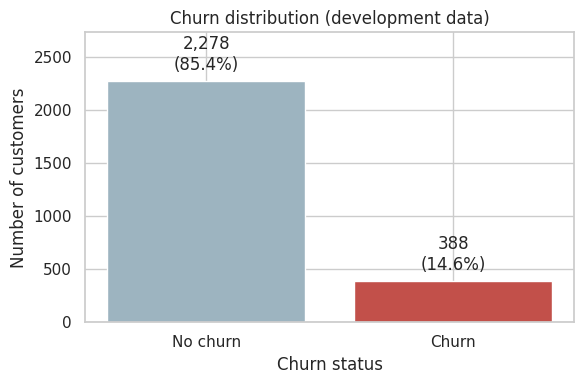

Saved: reports/tables/eda_churn_distribution.csv
Saved: reports/figures/eda_01_churn_distribution.png


In [2]:
# === 2. Churn distribution — development data only ===

# Validate the target.
if df[target].isna().any():
    raise ValueError("The target contains missing values.")

if not df[target].isin([False, True]).all():
    raise ValueError("Unexpected target values.")

# Fixed class order: No churn, then Churn.
churn_counts = (
    df[target]
    .value_counts()
    .reindex([False, True], fill_value=0)
    .rename(index={False: 'No churn', True: 'Churn'})
)

churn_table = pd.DataFrame({
    'Customers': churn_counts,
    'Share (%)': churn_counts / len(df) * 100
})
churn_table.index.name = 'Class'

display(churn_table.round({'Share (%)': 1}))

# Save the table with unrounded proportions.
churn_table.to_csv(TABLES / 'eda_churn_distribution.csv')

# Plot counts and proportions.
fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    churn_table.index,
    churn_table['Customers'],
    color=['#9DB4C0', '#C2504A']
)

for bar, share in zip(bars, churn_table['Share (%)']):
    ax.annotate(
        f"{int(bar.get_height()):,}\n({share:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        va='bottom'
    )

ax.set_title('Churn distribution (development data)')
ax.set_xlabel('Churn status')
ax.set_ylabel('Number of customers')
ax.set_ylim(0, churn_table['Customers'].max() * 1.20)

fig.tight_layout()
fig.savefig(
    FIGURES / 'eda_01_churn_distribution.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

print("Saved: reports/tables/eda_churn_distribution.csv")
print("Saved: reports/figures/eda_01_churn_distribution.png")

### Findings and implications

The development dataset contains 2,666 customer records: 388 churners (14.6%) and 2,278 non-churners (85.4%).

The target is imbalanced. Predicting no churn for every customer would achieve 85.4% accuracy but zero recall for churners. Accuracy alone would therefore provide an incomplete assessment.

Evaluation will include Average Precision, precision, recall, F1-score and ROC-AUC, alongside recall and lift at the top 10% and 20% contact capacities.

Random targeting has an expected precision equal to the churn proportion (approximately 14.6%) and an expected lift of 1. Selecting a fixed number k of customers uniformly at random has an expected recall of k divided by the total number of customers. At the nominal 10% and 20% contact capacities, this is approximately 10% and 20%, respectively. Actual results from an individual random selection will vary.

Contact capacity also limits the maximum achievable recall. Using floor rounding to avoid exceeding the specified capacity, 10% capacity allows 266 contacts out of 2,666 customers. Even a perfect ranking could therefore capture at most 266 of the 388 churners (68.6% recall).

At 20% capacity, 533 contacts are available, so capturing all 388 churners is theoretically possible with a perfect ranking. These capacity-dependent ceilings will be considered when interpreting recall at fixed contact capacity. The same floor rounding rule will be applied consistently to all models and targeting baselines.

## 3. Numerical feature distributions

Examine the scale, spread and shape of the numerical features retained after the audit, without reference to churn. Summary statistics include the mean, standard deviation, median and selected percentiles, together with skewness, the share of zero values and the share of values outside the 1.5 × IQR range.

The redundant charge variables and the categorical variables are excluded from this summary. IQR-based flags are descriptive only: extreme values will not be treated as errors or removed solely because they are unusual.

,count,mean,std,min,1%,25%,50%,75%,99%,max,Skewness,Zero share (%),Outside IQR bounds (%)
Feature,,,,,,,,,,,,,
Account length,2666.0,100.62,39.56,1.0,12.65,73.00,100.00,127.00,193.00,243.0,0.08,0.00,0.45
Number vmail messages,2666.0,8.02,13.61,0.0,0.00,0.00,0.00,19.00,43.00,50.0,1.27,72.51,0.08
Total day minutes,2666.0,179.48,54.21,0.0,50.92,143.40,179.95,215.90,302.87,350.8,-0.05,0.08,0.79
Total day calls,2666.0,100.31,19.99,0.0,54.00,87.00,101.00,114.00,146.35,160.0,-0.13,0.08,0.68
Total eve minutes,2666.0,200.39,50.95,0.0,80.39,165.30,200.90,235.10,318.87,363.7,-0.01,0.04,0.64
Total eve calls,2666.0,100.02,20.16,0.0,53.00,87.00,100.00,114.00,147.00,170.0,-0.07,0.04,0.56
Total night minutes,2666.0,201.17,50.78,43.7,80.10,166.92,201.15,236.48,319.14,395.0,0.02,0.00,0.83
Total night calls,2666.0,100.11,19.42,33.0,57.00,87.00,100.00,113.00,147.00,166.0,0.01,0.00,0.71
Total intl minutes,2666.0,10.24,2.79,0.0,3.36,8.50,10.20,12.10,16.63,20.0,-0.22,0.56,1.39


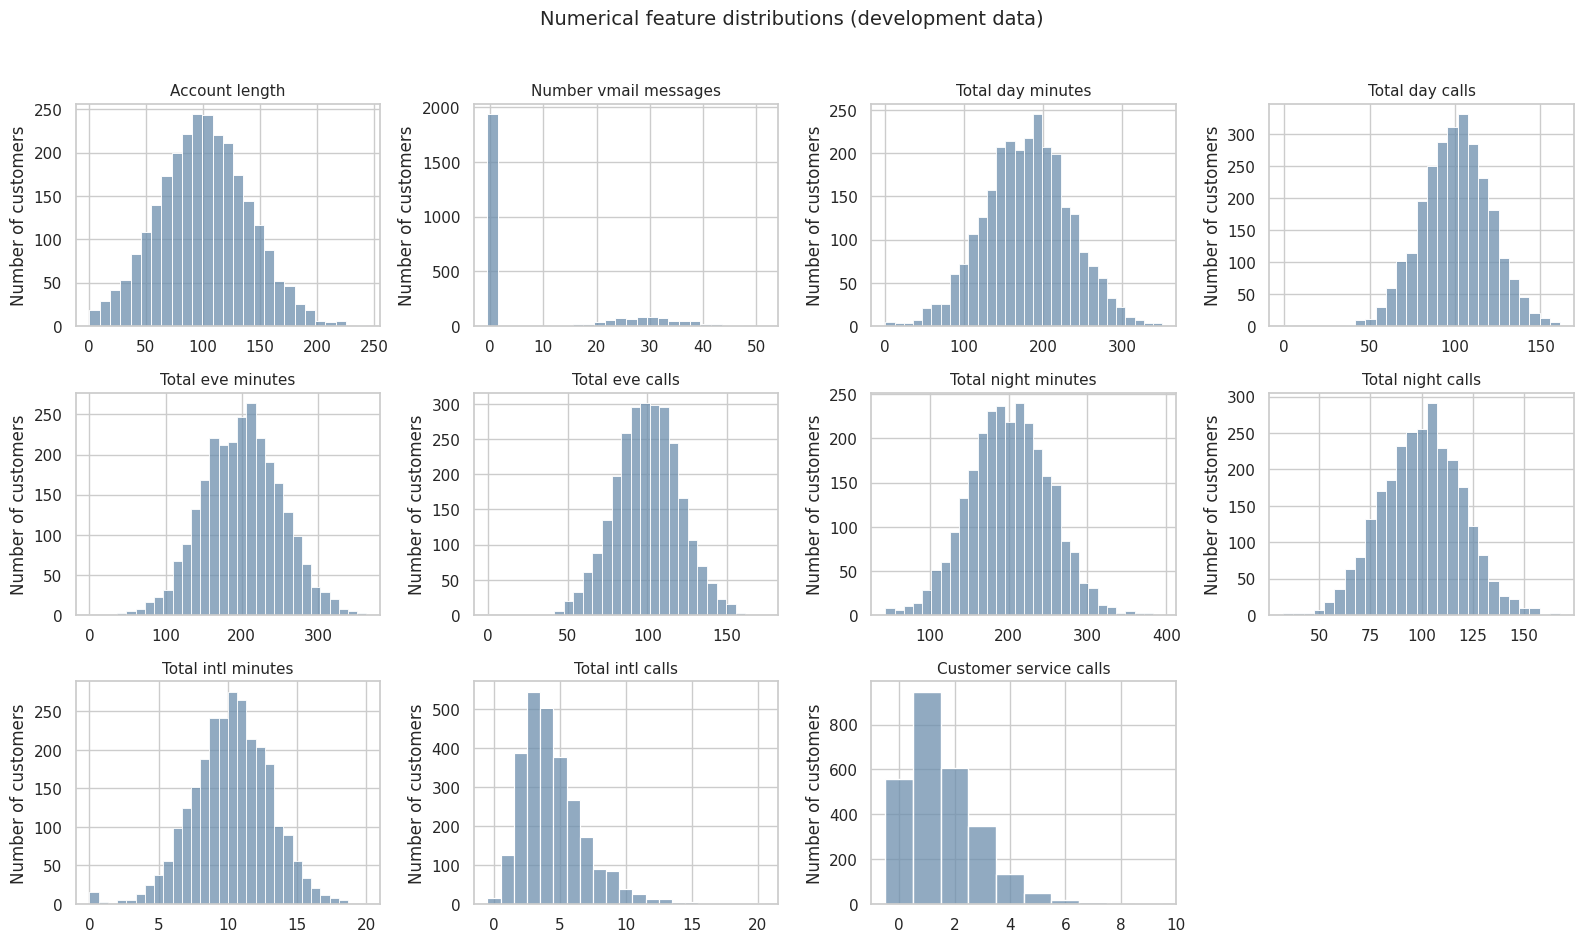

Saved: reports/tables/eda_numeric_summary.csv
Saved: reports/figures/eda_02_numeric_distributions.png


In [3]:
# === 3. Numerical feature distributions — development data only ===
num = df[numeric_cols]

# Descriptive statistics.
numeric_summary = num.describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T

numeric_summary.index.name = 'Feature'
numeric_summary['Skewness'] = num.skew()

# Use non-missing observations as the denominator.
valid_counts = num.notna().sum().replace(0, np.nan)

numeric_summary['Zero share (%)'] = (
    num.eq(0).sum().div(valid_counts).mul(100)
)

# Descriptive IQR flags; no records are removed.
q1 = num.quantile(0.25)
q3 = num.quantile(0.75)
iqr = q3 - q1

lower_bounds = q1 - 1.5 * iqr
upper_bounds = q3 + 1.5 * iqr

outside_iqr = (
    num.lt(lower_bounds)
    | num.gt(upper_bounds)
)

numeric_summary['Outside IQR bounds (%)'] = (
    outside_iqr.sum().div(valid_counts).mul(100)
)

# Display rounded statistics and save unrounded values.
display(numeric_summary.round(2))
numeric_summary.to_csv(TABLES / 'eda_numeric_summary.csv')

# Histograms:
# - Integer features with <= 25 unique values: unit-width bins.
# - Other integer features: grouped bins with half-integer boundaries.
# - Continuous features: 30 bins.
n_cols = 4
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 3.2 * n_rows),
    squeeze=False
)
axes = axes.ravel()

for ax, col in zip(axes, numeric_cols):
    values = num[col].dropna()

    if values.empty:
        ax.text(
            0.5, 0.5, 'No observed values',
            ha='center',
            va='center',
            transform=ax.transAxes
        )
    else:
        is_integer = values.mod(1).eq(0).all()
        is_discrete = values.nunique() <= 25 and is_integer

        if is_discrete:
            sns.histplot(
                x=values,
                ax=ax,
                discrete=True,
                color='#6C8EAD'
            )

        elif is_integer:
            value_range = int(values.max() - values.min() + 1)
            width = max(1, int(np.ceil(value_range / 30)))

            edges = np.arange(
                values.min() - 0.5,
                values.max() + 0.5 + width,
                width
            )

            sns.histplot(
                x=values,
                ax=ax,
                bins=edges,
                color='#6C8EAD'
            )

        else:
            sns.histplot(
                x=values,
                ax=ax,
                bins=30,
                color='#6C8EAD'
            )

    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Number of customers')

# Hide unused panels.
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)

fig.suptitle(
    'Numerical feature distributions (development data)',
    fontsize=14
)
fig.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    FIGURES / 'eda_02_numeric_distributions.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

print("Saved: reports/tables/eda_numeric_summary.csv")
print("Saved: reports/figures/eda_02_numeric_distributions.png")

### Findings and implications

Account length and most day, evening and night usage variables
show broadly unimodal, approximately symmetric distributions,
with skewness close to zero and similar means and medians.
These descriptive patterns do not establish normality.

Number vmail messages has a substantial concentration at zero
(72.5% of customers) and a separate spread of positive values,
mostly between about 20 and 40. Its relationship with Voice mail
plan will be examined before considering any feature changes.

Total intl calls (skewness 1.36) and Customer service calls
(skewness 1.10) are right-skewed, with most customers recording
relatively low counts and fewer customers recording high counts.

For Customer service calls, values of four or more (7.9% of
customers) fall outside the bounds Q1 − 1.5 × IQR and
Q3 + 1.5 × IQR. The highest counts involve very few customers:
eight customers recorded seven calls, one recorded eight calls,
and two recorded nine calls. These flags identify unusual values,
not confirmed data errors.

No observations will be removed solely because they fall in
the tails of these distributions. These univariate analyses
do not establish which features are associated with churn
or have predictive value.

Implications for modelling: numerical features will be standardised
within the cross-validation pipeline for Logistic Regression.
Random Forest does not require standardisation. Skewness alone
does not justify transforming or removing a feature.

Because high customer service call counts involve small groups,
churn rates by call count will be reported alongside group sizes
in the subsequent analysis.

## 4. Categorical features and churn

Compare churn rates across International plan, Voice mail plan,
Area code and State. Report each rate alongside its group size,
number of churners and a 95% Wilson confidence interval.
Rates based on small groups will be interpreted cautiously.

Summarise associations using Cramér's V and a chi-square test
of independence. Check expected cell frequencies before
interpreting chi-square p-values and flag cases where the
approximation may be unreliable.

These analyses are exploratory. They do not establish causal
effects or out-of-sample predictive value. P-values are not
adjusted for multiple comparisons and will not be used alone
to select features.

### 4.1 Association summary

In [4]:
# === 4.1 Churn rates and association tests — development data only ===
from scipy.stats import chi2_contingency

# Validate target and categorical inputs.
if df[target].isna().any() or not df[target].isin([False, True]).all():
    raise ValueError("The target must contain non-missing Boolean or 0/1 values.")

if df[categorical_cols].isna().any().any():
    raise ValueError("Missing categorical values require explicit handling.")

overall_rate = df[target].mean()


def wilson_ci(successes, n, z=1.96):
    """Pointwise 95% Wilson score interval for a proportion."""
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (centre - half).clip(0, 1), (centre + half).clip(0, 1)


def churn_by_group(col):
    """Group size, churn count, churn rate and Wilson interval."""
    g = (
        df.groupby(col, observed=True, sort=True)[target]
        .agg(Customers='size', Churners='sum')
    )
    g['Churn rate (%)'] = g['Churners'] / g['Customers'] * 100
    low, high = wilson_ci(g['Churners'], g['Customers'])
    g['CI low (%)'] = low * 100
    g['CI high (%)'] = high * 100
    return g


# Association tests and group-level tables.
assoc_rows = []
category_rates = {}

for col in categorical_cols:
    rates = churn_by_group(col)
    category_rates[col] = rates

    filename = col.lower().replace(' ', '_')
    rates.to_csv(TABLES / f'eda_churn_by_{filename}.csv')

    table = pd.crosstab(df[col], df[target])
    table = table.reindex(columns=[False, True], fill_value=0)

    if table.shape[0] < 2 or table.sum(axis=0).eq(0).any():
        raise ValueError(
            f"Association test requires at least two categories "
            f"and both target classes: {col}"
        )

    # Pearson chi-square without continuity correction.
    chi2, p_value, dof, expected = chi2_contingency(table, correction=False)

    cramers_v = np.sqrt(
        chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))
    )
    small_cell_share = (expected < 5).mean()

    assoc_rows.append({
        'Feature': col,
        'Categories': table.shape[0],
        'Chi-square': chi2,
        'Degrees of freedom': dof,
        'p-value (unadjusted)': p_value,
        "Cramér's V (uncorrected)": cramers_v,
        'Min expected count': expected.min(),
        'Cells with expected < 5': int((expected < 5).sum()),
        'Expected cells below 5 (%)': small_cell_share * 100,
        'Approximation flagged': bool(
            (expected < 1).any() or small_cell_share > 0.20
        )
    })

association = pd.DataFrame(assoc_rows).set_index('Feature')

print("Exploratory association summary:")
display(association.round(4))
association.to_csv(TABLES / 'eda_categorical_association.csv')

print("\nChi-square p-values are exploratory and unadjusted "
      "for multiple comparisons. Review flagged approximations.")
print("Uncorrected Cramér's V may be upward-biased, "
      "especially for features with many categories.")
print("\nSaved: reports/tables/eda_categorical_association.csv")
print("Saved: reports/tables/eda_churn_by_*.csv")

Exploratory association summary:


,Categories,Chi-square,Degrees of freedom,p-value (unadjusted),Cramér's V (uncorrected),Min expected count,Cells with expected < 5,Expected cells below 5 (%),Approximation flagged
Feature,,,,,,,,,
State,51,79.7986,50,0.0047,0.1730,3.4929,1,0.9804,False
Area code,3,0.1982,2,0.9056,0.0086,97.3638,0,0.0000,False
International plan,2,205.2821,1,0.0000,0.2775,39.2948,0,0.0000,False
Voice mail plan,2,26.2831,1,0.0000,0.0993,106.6782,0,0.0000,False



Chi-square p-values are exploratory and unadjusted for multiple comparisons. Review flagged approximations.
Uncorrected Cramér's V may be upward-biased, especially for features with many categories.

Saved: reports/tables/eda_categorical_association.csv
Saved: reports/tables/eda_churn_by_*.csv


### 4.2 International plan, Voice mail plan and Area code


International plan


,Customers,Churners,Churn rate (%),CI low (%),CI high (%)
International plan,,,,,
No,2396,270,11.27,10.06,12.60
Yes,270,118,43.70,37.92,49.67



Voice mail plan


,Customers,Churners,Churn rate (%),CI low (%),CI high (%)
Voice mail plan,,,,,
No,1933,323,16.71,15.11,18.44
Yes,733,65,8.87,7.02,11.15



Area code


,Customers,Churners,Churn rate (%),CI low (%),CI high (%)
Area code,,,,,
408,669,94,14.05,11.62,16.89
415,1318,195,14.80,12.98,16.81
510,679,99,14.58,12.13,17.43


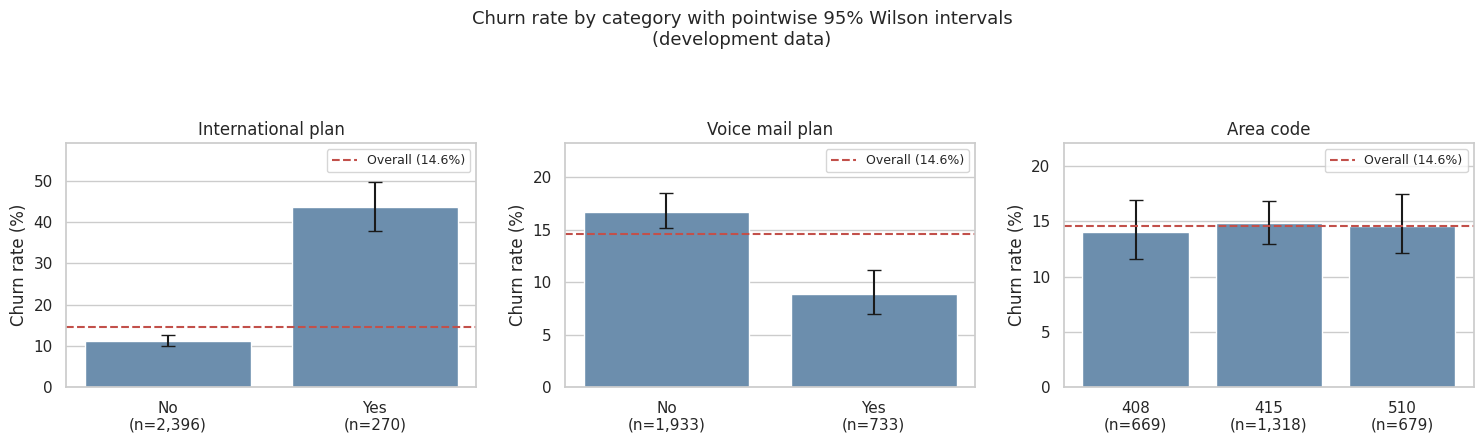


Wilson intervals are pointwise, not simultaneous intervals across all categories.
Saved: reports/figures/eda_03_churn_by_category.png


In [5]:
# === 4.2 Churn rates for low-cardinality features ===
plot_features = ['International plan', 'Voice mail plan', 'Area code']

for col in plot_features:
    print(f"\n{col}")
    display(category_rates[col].round(2))

# Plot churn rates with pointwise Wilson intervals.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col in zip(axes, plot_features):
    rates = category_rates[col]
    labels = rates.index.astype(str)

    yerr = np.vstack([
        np.maximum(0, rates['Churn rate (%)'] - rates['CI low (%)']),
        np.maximum(0, rates['CI high (%)'] - rates['Churn rate (%)'])
    ])

    ax.bar(labels, rates['Churn rate (%)'], yerr=yerr,
           capsize=5, color='#6C8EAD')
    ax.axhline(overall_rate * 100, color='#C2504A', linestyle='--',
               label=f'Overall ({overall_rate:.1%})')

    upper_limit = max(rates['CI high (%)'].max(), overall_rate * 100)
    ax.set_ylim(0, min(100, upper_limit * 1.15 + 2))

    # Group sizes beneath each category label.
    ax.set_xticks(np.arange(len(rates)))
    ax.set_xticklabels([
        f"{label}\n(n={int(n):,})"
        for label, n in zip(labels, rates['Customers'])
    ])

    ax.set_title(col)
    ax.set_ylabel('Churn rate (%)')
    ax.grid(axis='x', visible=False)
    ax.legend(loc='upper right', fontsize=9)

fig.suptitle('Churn rate by category with pointwise 95% Wilson intervals\n'
             '(development data)', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(FIGURES / 'eda_03_churn_by_category.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("\nWilson intervals are pointwise, not simultaneous "
      "intervals across all categories.")
print("Saved: reports/figures/eda_03_churn_by_category.png")

### Findings and implications

International plan shows the strongest observed association with churn among the categorical features examined (uncorrected Cramér's V = 0.28). Customers with the plan had a churn rate of 43.7% (95% Wilson CI: 37.9–49.7%; n = 270), compared with 11.3% among customers without it (CI: 10.1–12.6%; n = 2,396).

International-plan customers represent 10.1% of the development data and include 118 of the 388 churners (30.4%). This identifies a relatively high-risk group but leaves most churners outside the group. International plan is therefore a candidate for a simple targeting baseline, to be evaluated at the specified contact capacities during model development.

Voice mail plan shows a smaller association (V = 0.10). Customers without the plan had a churn rate of 16.7% (n = 1,933), compared with 8.9% among those with it (n = 733). This difference does not establish that subscribing to voice mail reduces churn.

Area code shows little evidence of an association with churn when examined on its own (p = 0.91; V = 0.01). Churn rates range from 14.1% to 14.8%, with substantially overlapping Wilson intervals. This does not rule out predictive value in combination with other features.

State will be examined separately in Section 4.3 to assess category frequencies and uncertainty in state-level churn rates. Uncorrected Cramér's V can be upward-biased for features with many categories.

These findings are exploratory associations, not causal effects or evidence of out-of-sample predictive performance. P-values are unadjusted for multiple comparisons, and the Wilson intervals are pointwise. Proposed feature exclusions or targeting rules will be evaluated using development-data cross-validation rather than selected solely from these descriptive results.

### 4.3 State

State contains 51 categories. State-level churn rates are examined
alongside group sizes and pointwise 95% Wilson confidence intervals.
Estimates based on smaller groups are interpreted cautiously.

States are displayed in alphabetical order rather than ranked
by observed churn rate. The overall development churn rate is
included as a descriptive reference, not as a formal test of
differences between individual states.

The uncorrected Cramér's V is compared with a bias-corrected
estimate to assess the influence of category count on the
association measure. Neither measure establishes causal effects
or out-of-sample predictive value.

State will not be retained, grouped or excluded solely because
of individual churn rates or confidence intervals. Any proposed
change in feature handling will be evaluated during model
development using cross-validation.

States: 51
Customers per state: min 24, median 51, max 88
States with fewer than 40 customers: 4

Cramér's V uncorrected: 0.173
Cramér's V bias-corrected: 0.106


,Customers,Churners,Churn rate (%),CI low (%),CI high (%)
State,,,,,
AK,43,3,6.98,2.40,18.61
AL,66,7,10.61,5.23,20.31
AR,47,11,23.40,13.60,37.22
AZ,45,3,6.67,2.29,17.86
CA,24,5,20.83,9.24,40.47
CO,59,7,11.86,5.87,22.52
CT,59,11,18.64,10.74,30.38
DC,45,5,11.11,4.84,23.50
DE,51,8,15.69,8.17,28.01


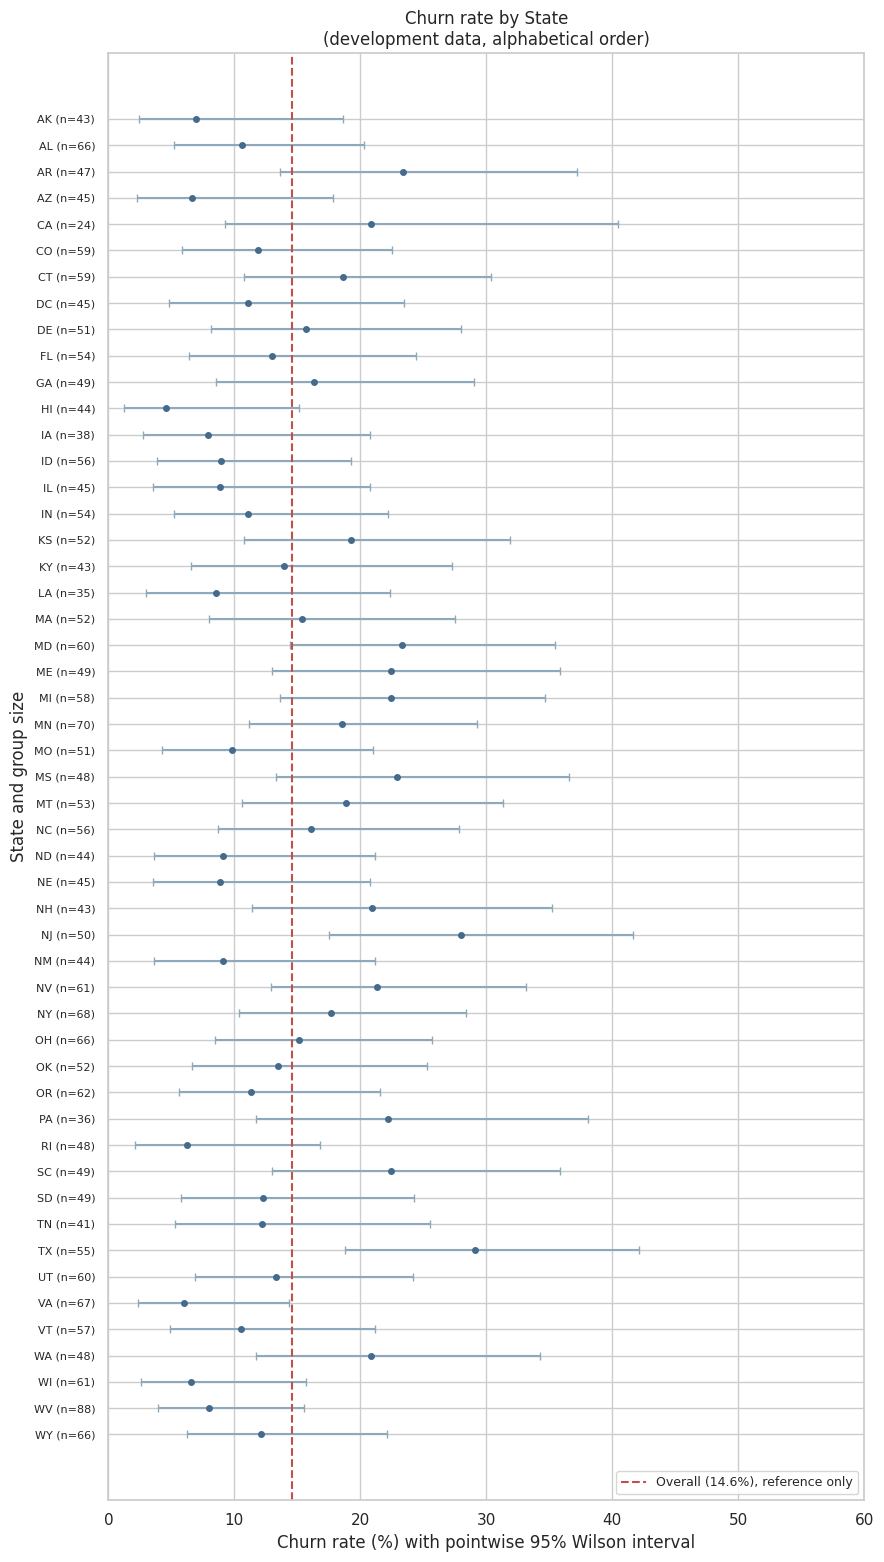


Intervals are pointwise. The overall churn rate is a descriptive reference, not a formal state-level test.
Saved: reports/figures/eda_04_churn_by_state.png


In [6]:
# === 4.3 State — development data only ===
state_rates = category_rates['State'].copy().sort_index()

# Group-size summary; 40 is descriptive, not an exclusion threshold.
sizes = state_rates['Customers']

print(f"States: {len(state_rates)}")
print(
    f"Customers per state: min {sizes.min()}, "
    f"median {sizes.median():.0f}, max {sizes.max()}"
)
print(f"States with fewer than 40 customers: {(sizes < 40).sum()}")


def cramers_v_corrected(table):
    """Bias-corrected Cramér's V."""
    observed = table.to_numpy()

    if min(table.shape) < 2:
        return np.nan

    n = observed.sum()
    if n <= 1:
        return np.nan

    chi2 = chi2_contingency(table, correction=False)[0]
    r, k = table.shape

    phi2 = chi2 / n
    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = r - (r - 1)**2 / (n - 1)
    k_corr = k - (k - 1)**2 / (n - 1)
    denominator = min(r_corr - 1, k_corr - 1)

    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denominator)


# Compare uncorrected and bias-corrected association measures.
state_table = pd.crosstab(df['State'], df[target])

v_uncorrected = association.loc[
    'State', "Cramér's V (uncorrected)"
]
v_corrected = cramers_v_corrected(state_table)

print(f"\nCramér's V uncorrected: {v_uncorrected:.3f}")
print(f"Cramér's V bias-corrected: {v_corrected:.3f}")

# Display all state-level estimates in alphabetical order.
display(state_rates.round(2))

# The state-rate CSV was already saved in Section 4.1.
# Do not save a duplicate here.

# Dot plot with pointwise Wilson confidence intervals.
plot_table = state_rates.reset_index()
positions = np.arange(len(plot_table))

rate = plot_table['Churn rate (%)'].to_numpy()
ci_low = plot_table['CI low (%)'].to_numpy()
ci_high = plot_table['CI high (%)'].to_numpy()

errors = np.vstack([
    np.maximum(0, rate - ci_low),
    np.maximum(0, ci_high - rate)
])

fig, ax = plt.subplots(
    figsize=(9, 0.28 * len(plot_table) + 1.5)
)

ax.errorbar(
    rate,
    positions,
    xerr=errors,
    fmt='o',
    markersize=4,
    color='#456B8C',
    ecolor='#8FA9BC',
    capsize=3
)

ax.set_yticks(positions)
ax.set_yticklabels(
    [
        f"{state} (n={int(n):,})"
        for state, n in zip(
            plot_table['State'],
            plot_table['Customers']
        )
    ],
    fontsize=8
)
ax.invert_yaxis()

ax.axvline(
    overall_rate * 100,
    color='#C2504A',
    linestyle='--',
    label=f'Overall ({overall_rate:.1%}), reference only'
)

upper_limit = max(
    60,
    np.ceil(ci_high.max() / 10) * 10
)
ax.set_xlim(0, min(100, upper_limit))

ax.set_xlabel(
    'Churn rate (%) with pointwise 95% Wilson interval'
)
ax.set_ylabel('State and group size')
ax.set_title(
    'Churn rate by State\n'
    '(development data, alphabetical order)'
)
ax.legend(loc='lower right', fontsize=9)

fig.tight_layout()
fig.savefig(
    FIGURES / 'eda_04_churn_by_state.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

print(
    "\nIntervals are pointwise. The overall churn rate is "
    "a descriptive reference, not a formal state-level test."
)
print("Saved: reports/figures/eda_04_churn_by_state.png")

### Findings and implications

State contains 51 categories, with group sizes ranging from 24 to 88 customers and a median of 51. Four categories contain fewer than 40 customers.

Observed churn rates vary across states. For example, Texas has a rate of 29.1% (16 of 55; 95% Wilson CI: 18.8–42.1%), while Hawaii has a rate of 4.5% (2 of 44; CI: 1.3–15.1%). These examples illustrate the observed variation rather than establishing a reliable ranking of states. Many intervals are wide and overlap substantially.

The uncorrected Cramér's V is 0.173, compared with 0.106 after bias correction. The reduction indicates that accounting for the number of categories materially affects the estimated association strength, and the corrected value suggests a relatively weak association.

The overall development churn rate is shown as a descriptive reference. Whether an individual state's pointwise interval includes this rate is not treated as a formal significance test. The intervals do not provide simultaneous 95% coverage across all states.

State will initially be retained as a categorical feature. One-hot encoding produces 51 indicator columns, or 50 if a reference category is dropped. This increases model dimensionality and may contribute to overfitting, depending on regularisation and model complexity.

These results alone do not justify grouping or excluding states, or prioritising retention contacts by state. The usefulness of State will be assessed during model development through cross-validation, with encoding fitted within training folds and unseen categories handled explicitly.

## 5. Numerical features and churn

### 5.1 Comparison by churn status

Compare each retained numerical feature between churners and
non-churners using group medians and means, a univariate ROC-AUC
and a two-sided Mann–Whitney U test.

The univariate AUC describes how well the raw feature values
rank churners above non-churners. An AUC above 0.5 indicates
that higher values tend to occur among churners; an AUC below
0.5 indicates the reverse. Values near 0.5 suggest little
directional ranking ability, but do not rule out nonlinear
relationships.

AUC is calculated on the development data without fitting a
model and is descriptive, not an estimate of out-of-sample
predictive performance.

The Mann–Whitney U test assesses differences in rank distributions;
it is not generally a test of medians alone. Tied values will be
accounted for using the asymptotic method. P-values are unadjusted
for multiple comparisons and will not be used alone to select
features. Observed associations do not establish causal effects.

,Median (churn),Median (no churn),Mean (churn),Mean (no churn),Univariate AUC,Separation |AUC - 0.5|,Direction,Mann-Whitney p (unadjusted)
Feature,,,,,,,,
Account length,103.00,100.00,102.3196,100.3310,0.5139,0.0139,Higher values rank toward churn,0.3821
Number vmail messages,0.00,0.00,5.1701,8.5075,0.4407,0.0593,Lower values rank toward churn,0.0000
Total day minutes,214.95,177.90,205.1812,175.1043,0.6334,0.1334,Higher values rank toward churn,0.0000
Total day calls,103.00,100.00,101.1959,100.1594,0.5235,0.0235,Higher values rank toward churn,0.1385
Total eve minutes,209.00,199.55,209.3853,198.8534,0.5578,0.0578,Higher values rank toward churn,0.0003
Total eve calls,100.50,100.00,99.9485,100.0364,0.5005,0.0005,Higher values rank toward churn,0.9765
Total night minutes,204.95,200.00,205.3072,200.4641,0.5266,0.0266,Higher values rank toward churn,0.0941
Total night calls,101.00,100.00,100.6830,100.0079,0.5085,0.0085,Higher values rank toward churn,0.5935
Total intl minutes,10.80,10.20,10.8193,10.1378,0.5657,0.0657,Higher values rank toward churn,0.0000


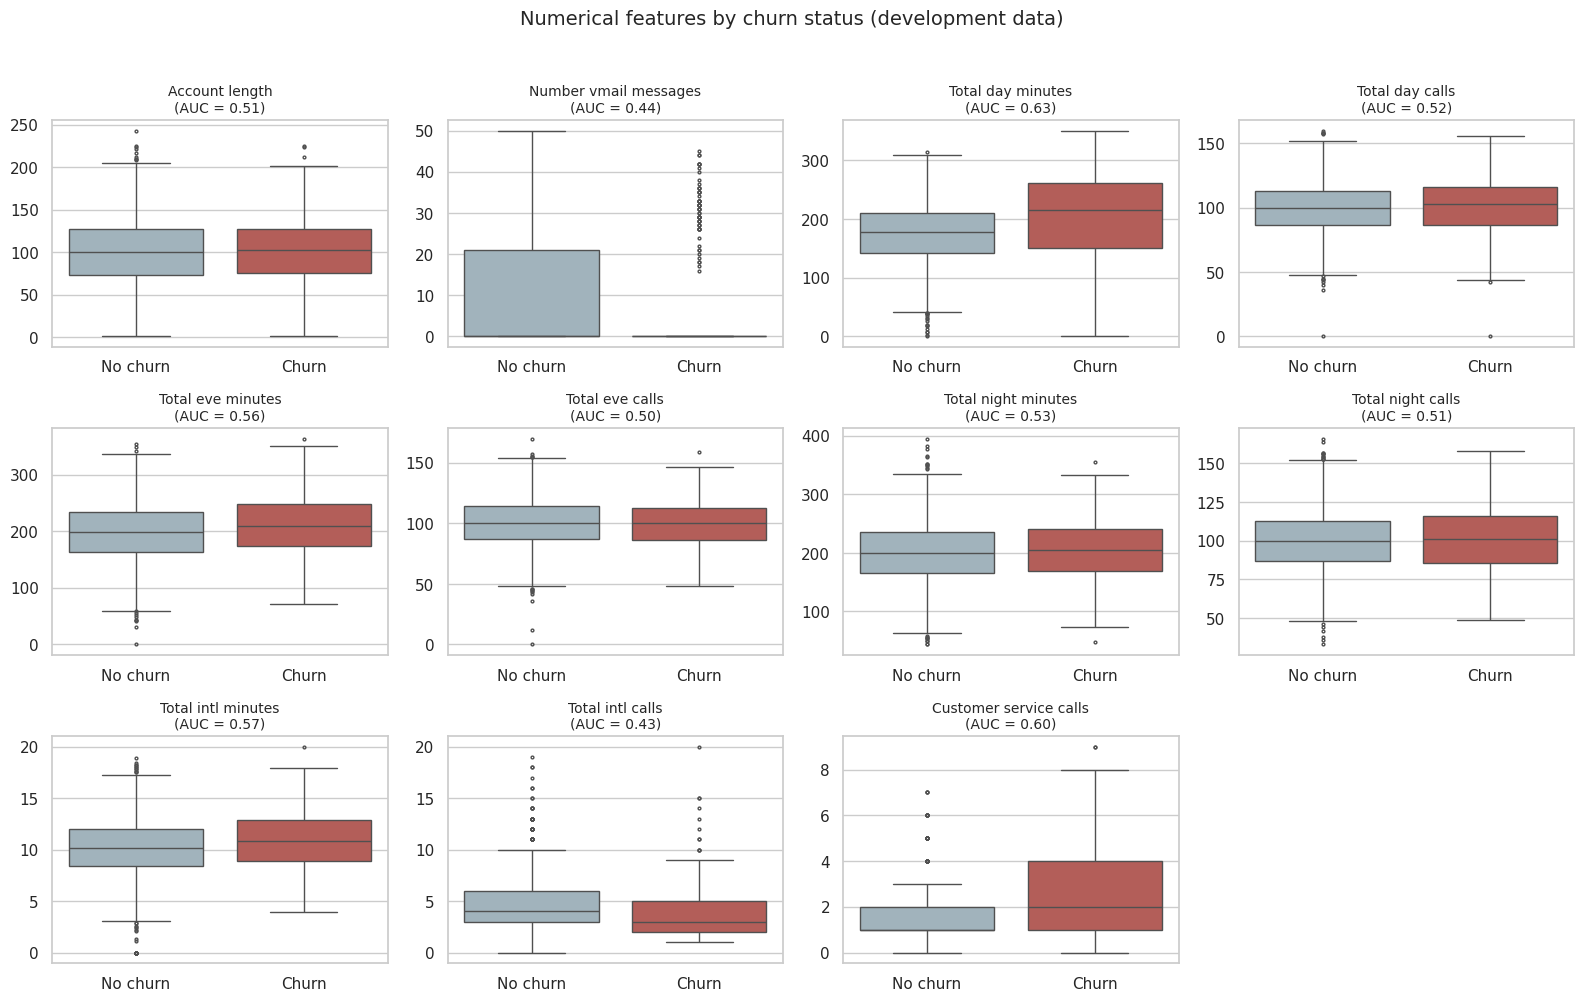

Saved: reports/tables/eda_numeric_by_churn.csv
Saved: reports/figures/eda_05_numeric_by_churn.png


In [7]:
# === 5.1 Numerical features by churn status — development data only ===
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

# Validate the target and numerical inputs.
if df[target].isna().any() or not df[target].isin([False, True]).all():
    raise ValueError("The target must contain non-missing Boolean or 0/1 values.")

y = df[target].astype(int)

if y.nunique() != 2:
    raise ValueError("Both churn classes are required.")

if not np.isfinite(df[numeric_cols].to_numpy(dtype=float)).all():
    raise ValueError("Numerical features contain missing or infinite values.")

rows = []

for col in numeric_cols:
    churn_vals = df.loc[y == 1, col]
    stay_vals = df.loc[y == 0, col]

    # Raw feature values are used as ranking scores.
    auc = roc_auc_score(y, df[col])

    direction = (
        'Higher values rank toward churn'
        if auc > 0.5
        else 'Lower values rank toward churn'
        if auc < 0.5
        else 'No directional separation'
    )

    # Asymptotic test with tie correction.
    p_value = mannwhitneyu(
        churn_vals,
        stay_vals,
        alternative='two-sided',
        method='asymptotic'
    ).pvalue

    rows.append({
        'Feature': col,
        'Median (churn)': churn_vals.median(),
        'Median (no churn)': stay_vals.median(),
        'Mean (churn)': churn_vals.mean(),
        'Mean (no churn)': stay_vals.mean(),
        'Univariate AUC': auc,
        'Separation |AUC - 0.5|': abs(auc - 0.5),
        'Direction': direction,
        'Mann-Whitney p (unadjusted)': p_value
    })

numeric_assoc = pd.DataFrame(rows).set_index('Feature')

# Display rounded results; save full-precision values.
display(numeric_assoc.round(4))
numeric_assoc.to_csv(TABLES / 'eda_numeric_by_churn.csv')

# Boxplots by churn status.
# Points beyond the whiskers are displayed, not removed.
n_cols = 4
n_rows = int(np.ceil(len(numeric_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 3.4 * n_rows),
    squeeze=False
)
axes = axes.ravel()

# Temporary plotting copy with readable class labels.
plot_data = df[numeric_cols].copy()
plot_data['Churn status'] = y.map({
    0: 'No churn',
    1: 'Churn'
})

class_order = ['No churn', 'Churn']
colours = {
    'No churn': '#9DB4C0',
    'Churn': '#C2504A'
}

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        data=plot_data,
        x='Churn status',
        y=col,
        hue='Churn status',
        order=class_order,
        hue_order=class_order,
        palette=colours,
        dodge=False,
        legend=False,
        fliersize=2,
        ax=ax
    )

    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_title(
        f"{col}\n"
        f"(AUC = {numeric_assoc.loc[col, 'Univariate AUC']:.2f})",
        fontsize=10
    )

# Hide unused panels.
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)

fig.suptitle(
    'Numerical features by churn status (development data)',
    fontsize=14
)
fig.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    FIGURES / 'eda_05_numeric_by_churn.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

print("Saved: reports/tables/eda_numeric_by_churn.csv")
print("Saved: reports/figures/eda_05_numeric_by_churn.png")

### Findings and implications

Total day minutes shows the greatest directional separation among the numerical features examined (univariate AUC = 0.633). Churners had a median of 214.95 minutes, compared with 177.90 among non-churners. However, the distributions overlap substantially, so this feature alone does not clearly separate the two groups. Possible nonlinear patterns in its relationship with churn will be explored in Section 5.3.

Customer service calls also shows an association with churn (AUC = 0.599). Churners recorded a median of two calls, compared with one among non-churners. The relationship will be examined by individual call count in Section 5.2, alongside group sizes and confidence intervals. The timing uncertainty identified in the audit remains unresolved.

Total intl minutes and Total eve minutes show smaller directional differences (AUC = 0.566 and 0.558, respectively). Lower values of Total intl calls and Number vmail messages tend to occur among churners (AUC = 0.427 and 0.441). Both churners and non-churners have a median of zero voice mail messages, illustrating that equal medians can coexist with differences in the distributions.

Account length, Total day calls, Total eve calls, Total night minutes and Total night calls have AUC values close to 0.5, indicating limited directional ranking ability when examined individually. This does not rule out nonlinear relationships or predictive value in combination with other features. For day and evening usage, call duration in minutes shows more directional separation than the number of calls.

The numerical features examined show limited directional discrimination individually. The largest absolute deviation from an AUC of 0.5 is 0.133, for Total day minutes. Whether combining features and capturing nonlinear relationships improves ranking will be evaluated during model development.

Several Mann–Whitney tests yield small unadjusted p-values, but statistical evidence of a distributional difference does not imply strong predictive discrimination. Values displayed as 0.0000 are rounded and will be reported as p < 0.001.

These analyses are descriptive and use development data only. No feature will be removed solely because of its univariate AUC or p-value. Predictive usefulness will be evaluated through cross-validation, and the predefined sensitivity analysis without Customer service calls will be retained.

### 5.2 Customer service calls

Churn rates are reported for each observed number of customer service calls, alongside group sizes, churner counts and pointwise 95% Wilson confidence intervals. Estimates for uncommon high call counts will be interpreted cautiously.

A cumulative threshold table shows, for each threshold k, the proportion of customers with at least k calls, their churn rate and the proportion of all churners they include.

The threshold table is descriptive. Any threshold selection for a rule-based baseline will be performed within the training folds and evaluated using the same cross-validation design as the models.

A threshold may select more or fewer customers than the specified contact capacity. Comparisons at 10% and 20% capacity will therefore use a predefined ranking and tie-breaking procedure that does not use validation or test labels.

The timing uncertainty identified in the audit remains unresolved: recorded service calls could include cancellation-related contacts. These associations do not establish causal effects or confirm that the feature was available before churn. The predefined sensitivity analysis without Customer service calls will be retained.

Churn by customer service call count:


,Customers,Churners,Churn rate (%),CI low (%),CI high (%)
Customer service calls,,,,,
0,555,79,14.23,11.57,17.39
1,945,99,10.48,8.68,12.59
2,608,62,10.20,8.04,12.86
3,348,37,10.63,7.81,14.31
4,133,64,48.12,39.80,56.54
5,49,29,59.18,45.25,71.78
6,17,10,58.82,36.01,78.39
7,8,5,62.50,30.57,86.32
8,1,1,100.00,20.65,100.00



Cumulative thresholds — descriptive development results:


,Customers,Share of customers (%),Churners,Churn rate (%),Share of all churners (%)
Threshold (calls >= k),,,,,
1,2111,79.18,309,14.64,79.64
2,1166,43.74,210,18.01,54.12
3,558,20.93,148,26.52,38.14
4,210,7.88,111,52.86,28.61
5,77,2.89,47,61.04,12.11
6,28,1.05,18,64.29,4.64
7,11,0.41,8,72.73,2.06
8,3,0.11,3,100.00,0.77
9,2,0.08,2,100.00,0.52


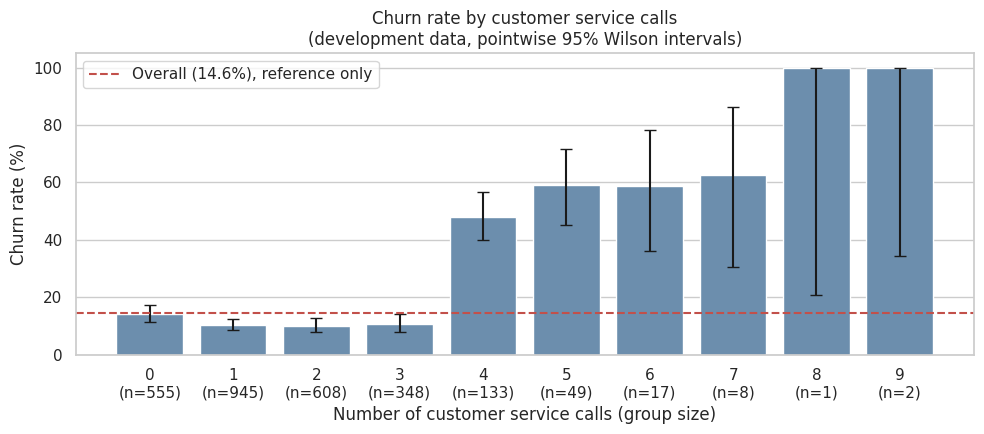


Threshold results are descriptive, not cross-validated performance estimates or fixed-capacity comparisons.
Saved: reports/tables/eda_churn_by_customer_service_calls.csv
Saved: reports/tables/eda_customer_service_thresholds.csv
Saved: reports/figures/eda_06_churn_by_customer_service_calls.png


In [8]:
# === 5.2 Customer service calls — development data only ===
cs_col = 'Customer service calls'

# Churn rate by individual call count.
# Reuses churn_by_group from Section 4.1.
cs_rates = churn_by_group(cs_col).sort_index()

print("Churn by customer service call count:")
display(cs_rates.round(2))

cs_rates.to_csv(
    TABLES / 'eda_churn_by_customer_service_calls.csv'
)

# Cumulative thresholds: customers with at least k calls.
total_churners = int(df[target].sum())
threshold_rows = []

for k in range(1, int(df[cs_col].max()) + 1):
    mask = df[cs_col] >= k
    n_k = int(mask.sum())
    churners_k = int(df.loc[mask, target].sum())

    threshold_rows.append({
        'Threshold (calls >= k)': k,
        'Customers': n_k,
        'Share of customers (%)': n_k / len(df) * 100,
        'Churners': churners_k,
        'Churn rate (%)': (
            churners_k / n_k * 100 if n_k else np.nan
        ),
        'Share of all churners (%)': (
            churners_k / total_churners * 100
            if total_churners else np.nan
        )
    })

cs_thresholds = (
    pd.DataFrame(threshold_rows)
    .set_index('Threshold (calls >= k)')
)

print("\nCumulative thresholds — descriptive development results:")
display(cs_thresholds.round(2))

cs_thresholds.to_csv(
    TABLES / 'eda_customer_service_thresholds.csv'
)

# Plot churn rates with pointwise Wilson intervals.
plot_table = cs_rates.reset_index()
x = np.arange(len(plot_table))

rate = plot_table['Churn rate (%)'].to_numpy()
ci_low = plot_table['CI low (%)'].to_numpy()
ci_high = plot_table['CI high (%)'].to_numpy()

yerr = np.vstack([
    np.maximum(0, rate - ci_low),
    np.maximum(0, ci_high - rate)
])

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.bar(
    x,
    rate,
    yerr=yerr,
    capsize=4,
    color='#6C8EAD'
)

ax.axhline(
    overall_rate * 100,
    color='#C2504A',
    linestyle='--',
    label=f'Overall ({overall_rate:.1%}), reference only'
)

ax.set_xticks(x)
ax.set_xticklabels([
    f"{int(calls)}\n(n={int(n):,})"
    for calls, n in zip(
        plot_table[cs_col],
        plot_table['Customers']
    )
])

ax.set_xlabel('Number of customer service calls (group size)')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 105)
ax.set_title(
    'Churn rate by customer service calls\n'
    '(development data, pointwise 95% Wilson intervals)'
)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')

fig.tight_layout()
fig.savefig(
    FIGURES / 'eda_06_churn_by_customer_service_calls.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

print(
    "\nThreshold results are descriptive, not cross-validated "
    "performance estimates or fixed-capacity comparisons."
)
print("Saved: reports/tables/eda_churn_by_customer_service_calls.csv")
print("Saved: reports/tables/eda_customer_service_thresholds.csv")
print("Saved: reports/figures/eda_06_churn_by_customer_service_calls.png")

### Findings and implications

The relationship between customer service calls and churn is not a steady increase across all call counts. Observed churn rates remain comparatively low for zero to three calls, followed by a marked increase at four calls. This pattern helps explain why the raw call count has only modest directional discrimination (AUC = 0.599) despite the elevated rates at higher counts.

Because the pattern is step-like, a single linear term in Logistic Regression may not represent it well, whereas tree-based models such as Random Forest can capture threshold effects directly. Whether this difference affects ranking performance will be evaluated through cross-validation.

Customers with at least four calls represent 7.88% of the development data (210 customers). This group contains 111 churners, giving a churn rate of 52.86% and covering 28.61% of all development churners.

Increasing the threshold to at least five calls raises the observed churn rate to 61.04%, but reduces coverage to 12.11% of all churners and selects only 2.89% of customers. This illustrates the trade-off between targeting precision and churner coverage.

The highest call-count groups are very small. The observed 100% churn rates at eight and nine calls are based on one and two customers, respectively, and have wide Wilson intervals. They should not be treated as reliable population rates.

A threshold of at least three calls selects 20.93% of customers, exceeding the 20% contact capacity, while at least four calls selects fewer than 10%. Neither threshold directly implements the required fixed-capacity comparison. A predefined ranking and label-independent tie-breaking procedure will therefore be used during model development.

These results are descriptive and do not establish a validated targeting rule or causal effect. Any threshold selection will be performed within training folds. The uncertain timing of service calls remains a potential leakage concern, and the predefined sensitivity analysis excluding this feature will be retained.

### 5.3 Total day minutes

Explore the relationship between daytime call minutes and churn
using ten approximately equal-sized groups defined by development
data quantiles. Report group boundaries, customer counts, churner
counts and pointwise 95% Wilson confidence intervals.

Grouping helps visualise possible nonlinear patterns but can
conceal variation within groups. The groups are descriptive,
not proposed operational thresholds. Any model transformation
or threshold will require evaluation within cross-validation.

,Customers,Churners,Churn rate (%),CI low (%),CI high (%)
Total day minutes (quantile interval),,,,,
"(-0.001, 110.4]",267,30,11.24,7.98,15.59
"(110.4, 134.3]",267,42,15.73,11.85,20.58
"(134.3, 150.6]",267,25,9.36,6.42,13.46
"(150.6, 165.8]",266,30,11.28,8.02,15.64
"(165.8, 179.95]",266,31,11.65,8.33,16.07
"(179.95, 194.3]",268,15,5.60,3.42,9.03
"(194.3, 207.7]",266,14,5.26,3.16,8.64
"(207.7, 223.5]",267,23,8.61,5.81,12.59
"(223.5, 248.85]",265,56,21.13,16.65,26.44


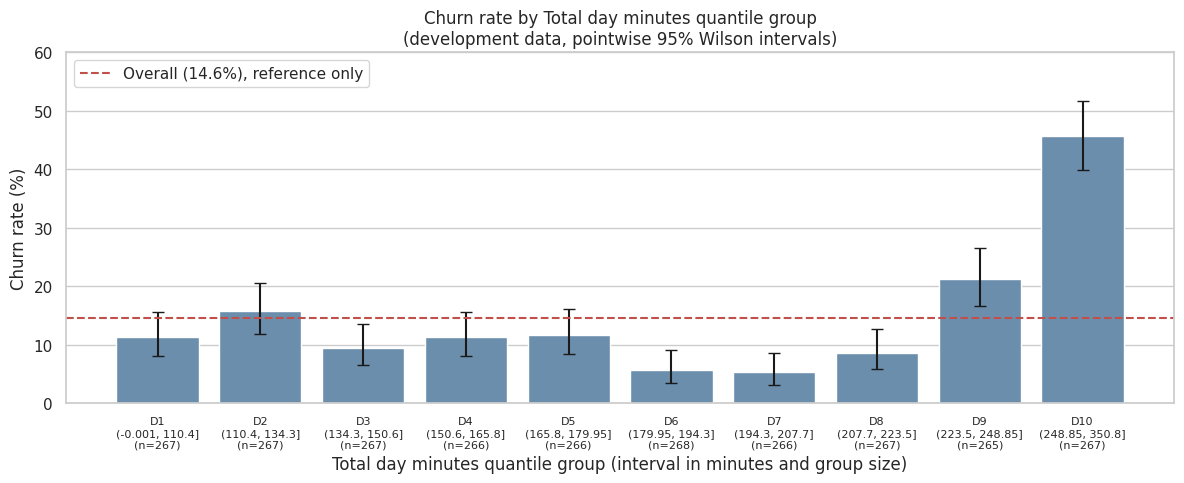


Quantile boundaries are descriptive and based on the full development data.
The first displayed interval may start slightly below the observed minimum so that the minimum is included.
These groups are not operational thresholds. Any binning used in modelling must be fitted within training folds.
Saved: reports/tables/eda_churn_by_day_minutes_decile.csv
Saved: reports/figures/eda_07_churn_by_day_minutes_decile.png


In [9]:
# === 5.3 Total day minutes by decile — development data only ===
dm_col = 'Total day minutes'

# Approximately equal-sized quantile groups, for descriptive EDA only.
decile = pd.qcut(
    df[dm_col],
    q=10,
    duplicates='drop'
)

dm_rates = (
    df.groupby(decile, observed=True, sort=True)[target]
    .agg(Customers='size', Churners='sum')
)

dm_rates['Churn rate (%)'] = (
    dm_rates['Churners'] / dm_rates['Customers'] * 100
)

low, high = wilson_ci(
    dm_rates['Churners'],
    dm_rates['Customers']
)
dm_rates['CI low (%)'] = low * 100
dm_rates['CI high (%)'] = high * 100

# Preserve interval notation: open left boundary, closed right boundary.
dm_rates.index = [
    f"({iv.left:g}, {iv.right:g}]"
    for iv in dm_rates.index
]
dm_rates.index.name = f'{dm_col} (quantile interval)'

display(dm_rates.round(2))

dm_rates.to_csv(
    TABLES / 'eda_churn_by_day_minutes_decile.csv'
)

# Plot churn rates with pointwise Wilson confidence intervals.
x = np.arange(len(dm_rates))
rate = dm_rates['Churn rate (%)'].to_numpy()

yerr = np.vstack([
    np.maximum(
        0,
        rate - dm_rates['CI low (%)'].to_numpy()
    ),
    np.maximum(
        0,
        dm_rates['CI high (%)'].to_numpy() - rate
    )
])

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    x,
    rate,
    yerr=yerr,
    capsize=4,
    color='#6C8EAD'
)

ax.axhline(
    overall_rate * 100,
    color='#C2504A',
    linestyle='--',
    label=f'Overall ({overall_rate:.1%}), reference only'
)

ax.set_xticks(x)
ax.set_xticklabels(
    [
        f"D{i + 1}\n{label}\n(n={int(n):,})"
        for i, (label, n) in enumerate(
            zip(dm_rates.index, dm_rates['Customers'])
        )
    ],
    fontsize=8
)

ax.set_xlabel(
    'Total day minutes quantile group '
    '(interval in minutes and group size)'
)
ax.set_ylabel('Churn rate (%)')

upper_limit = max(
    60,
    np.ceil(dm_rates['CI high (%)'].max() / 10) * 10
)
ax.set_ylim(0, min(100, upper_limit))

ax.set_title(
    'Churn rate by Total day minutes quantile group\n'
    '(development data, pointwise 95% Wilson intervals)'
)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')

fig.tight_layout()
fig.savefig(
    FIGURES / 'eda_07_churn_by_day_minutes_decile.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

print(
    "\nQuantile boundaries are descriptive and based on "
    "the full development data."
)
print(
    "The first displayed interval may start slightly below "
    "the observed minimum so that the minimum is included."
)
print(
    "These groups are not operational thresholds. Any binning "
    "used in modelling must be fitted within training folds."
)
print("Saved: reports/tables/eda_churn_by_day_minutes_decile.csv")
print("Saved: reports/figures/eda_07_churn_by_day_minutes_decile.png")

### Findings and implications

The relationship between Total day minutes and churn is not
a steady increase across the distribution. Churn rates fluctuate
across the lower and middle quantile groups, reaching 5.60%
and 5.26% in D6 and D7, before increasing to 21.13% in D9
and 45.69% in D10.

The highest-minute group, above 248.85 minutes, contains
267 customers and 122 churners. Its observed churn rate is
45.69% (95% Wilson CI: 39.82–51.69%), compared with the overall
development rate of 14.6%. This group includes 31.4% of all
388 development churners.

These grouped results suggest a nonlinear marginal relationship,
with elevated churn concentrated at high daytime usage.
They motivate comparing the linear Logistic Regression benchmark
with Random Forest, which can represent nonlinear patterns.
Whether this improves ranking performance must be established
through cross-validation.

The highest quantile group contains 267 customers, whereas
the predefined 10% contact capacity allows 266 contacts.
Its results are therefore not an exact Recall@10% or Lift@10%
evaluation.

Quantile boundaries depend on the development sample and
are descriptive rather than operational thresholds. Grouping
can conceal within-group variation, and the pointwise Wilson
intervals are not simultaneous confidence intervals or formal
tests against the overall rate.

No threshold or feature transformation will be adopted solely
from this plot. Any such choice will be evaluated within
development-data cross-validation. These associations do not
establish that high daytime usage causes churn.

## 6. Relationships between features

### 6.1 Correlation between numerical features

Calculate pairwise Spearman rank correlations between the
retained numerical features. Spearman correlation describes
monotonic relationships and is generally less sensitive to
extreme magnitudes than Pearson correlation.

Strong correlations may indicate overlapping information and
potential collinearity concerns for Logistic Regression, but
will not automatically lead to feature exclusion. Weak pairwise
correlations do not rule out nonlinear dependencies or
multicollinearity involving several features.

The redundant charge variables are excluded from this analysis.
Only development data are used, and Churn is not included
in the feature correlation matrix.

Largest absolute correlation between different features: 0.034

Five strongest pairs:


Spearman rho  |rho|
Feature 1             Feature 2                                  
Account length        Total day calls                0.034  0.034
                      Total intl calls               0.027  0.027
Total day minutes     Customer service calls        -0.025  0.025
Total day calls       Total intl minutes             0.024  0.024
Number vmail messages Total day minutes              0.024  0.024

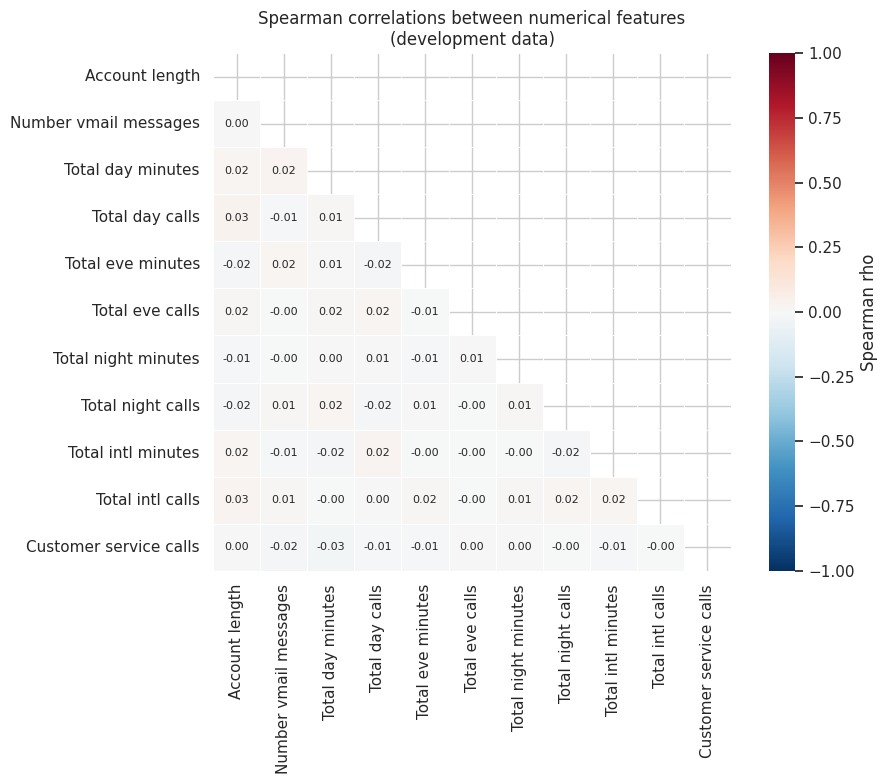

Saved: reports/tables/eda_spearman_correlations.csv
Saved: reports/figures/eda_08_spearman_correlations.png


In [10]:
# === 6.1 Spearman correlations between numerical features ===
spearman = df[numeric_cols].corr(method='spearman')
spearman.to_csv(TABLES / 'eda_spearman_correlations.csv')

# Strongest off-diagonal pairs (each pair listed once)
upper = spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), k=1))
top_pairs = (
    upper.stack()
    .rename('Spearman rho')
    .to_frame()
    .assign(**{'|rho|': lambda d: d['Spearman rho'].abs()})
    .sort_values('|rho|', ascending=False)
)
top_pairs.index.names = ['Feature 1', 'Feature 2']

print(f"Largest absolute correlation between different features: "
      f"{top_pairs['|rho|'].max():.3f}")
print("\nFive strongest pairs:")
display(top_pairs.head(5).round(3))

# Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones(spearman.shape, dtype=bool))
sns.heatmap(spearman, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5,
            cbar_kws={'label': 'Spearman rho'},
            annot_kws={'size': 8}, ax=ax)
ax.set_title('Spearman correlations between numerical features\n'
             '(development data)')
fig.tight_layout()
fig.savefig(FIGURES / 'eda_08_spearman_correlations.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("Saved: reports/tables/eda_spearman_correlations.csv")
print("Saved: reports/figures/eda_08_spearman_correlations.png")

### Findings and implications

Pairwise Spearman correlations between the retained numerical features are very small. The largest absolute correlation is 0.034, between Account length and Total day calls. No strong pairwise monotonic relationships are evident in the development data after excluding the redundant charge variables.

This analysis provides no basis for further numerical feature exclusion due to strong pairwise rank correlation. However, near-zero Spearman correlations do not establish independence or rule out nonlinear dependencies or multicollinearity involving several features.

Within-period call counts and total minutes also have near-zero Spearman correlations; for example, Total day minutes and Total day calls have rho approximately 0.01. This describes the observed sample but does not establish how the data were generated. Neither low correlations nor approximately symmetric distributions are sufficient to identify synthetic data.

The poorly documented collection context remains a limitation. Generalisability to an operational customer population would require validation on appropriately documented external data.

The matrix excludes categorical variables and therefore does not assess potential overlap between Voice mail plan and Number vmail messages. This relationship will be examined separately in Section 6.2.

These results concern relationships between predictors, not their associations with churn or their out-of-sample predictive value.

### 6.2 Voice mail plan and message counts

Examine whether Voice mail plan overlaps with the information in Number vmail messages. Report zero and positive message counts within each plan category, together with descriptive statistics for message counts.

The analysis does not use churn labels. Any observed overlap will inform feature handling, but does not automatically justify excluding either feature.

In [11]:
# === 6.2 Voice mail plan and message counts — development data only ===
vm_plan = 'Voice mail plan'
vm_msgs = 'Number vmail messages'

# Validate inputs before classifying message counts.
if df[[vm_plan, vm_msgs]].isna().any().any():
    raise ValueError("Missing values require review.")

if not df[vm_plan].isin(['Yes', 'No']).all():
    raise ValueError("Unexpected plan categories.")

if not np.isfinite(df[vm_msgs].to_numpy(dtype=float)).all():
    raise ValueError("Message counts contain non-finite values.")

if (
    df[vm_msgs].lt(0).any()
    or df[vm_msgs].mod(1).ne(0).any()
):
    raise ValueError("Message counts must be non-negative integers.")

# 1. Zero versus positive message counts within each plan category.
message_status = df[vm_msgs].gt(0).map({
    False: 'Zero messages',
    True: 'Positive messages'
})
message_status.name = 'Message status'

consistency = pd.crosstab(
    df[vm_plan],
    message_status,
    margins=True,
    margins_name='Total'
).reindex(
    index=['No', 'Yes', 'Total'],
    columns=['Zero messages', 'Positive messages', 'Total'],
    fill_value=0
)

print("Plan status vs message counts:")
display(consistency)

# These combinations are descriptive, not confirmed data errors.
plan_with_zero = int((
    df[vm_plan].eq('Yes') & df[vm_msgs].eq(0)
).sum())

messages_without_plan = int((
    df[vm_plan].eq('No') & df[vm_msgs].gt(0)
).sum())

print(f"Plan = Yes with zero messages: {plan_with_zero}")
print(f"Plan = No with positive messages: {messages_without_plan}")

# 2. Summary of message counts by plan category.
msg_summary = (
    df.groupby(vm_plan)[vm_msgs]
    .describe()
    .reindex(['No', 'Yes'])
)

print("\nMessage counts by plan category:")
display(msg_summary.round(2))

# 3. Pearson correlation between the binary plan indicator
# and message counts (equivalent to point-biserial correlation).
plan_indicator = df[vm_plan].eq('Yes').astype(int)

if plan_indicator.nunique() > 1 and df[vm_msgs].nunique() > 1:
    pearson_r = np.corrcoef(
        plan_indicator,
        df[vm_msgs]
    )[0, 1]
else:
    pearson_r = np.nan

print(
    "\nPearson correlation "
    f"(plan indicator vs message count): {pearson_r:.3f}"
)

# Save tables without modifying the development data.
consistency.to_csv(
    TABLES / 'eda_voicemail_consistency.csv'
)
msg_summary.to_csv(
    TABLES / 'eda_voicemail_message_summary.csv'
)

print("\nSaved: reports/tables/eda_voicemail_consistency.csv")
print("Saved: reports/tables/eda_voicemail_message_summary.csv")

Plan status vs message counts:


Message status,Zero messages,Positive messages,Total
Voice mail plan,,,
No,1933,0,1933
Yes,0,733,733
Total,1933,733,2666


Plan = Yes with zero messages: 0
Plan = No with positive messages: 0

Message counts by plan category:


,count,mean,std,min,25%,50%,75%,max
Voice mail plan,,,,,,,,
No,1933.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0
Yes,733.0,29.18,7.52,4.0,24.0,29.0,34.0,50.0



Pearson correlation (plan indicator vs message count): 0.957

Saved: reports/tables/eda_voicemail_consistency.csv
Saved: reports/tables/eda_voicemail_message_summary.csv


### Findings and implications

Voice mail plan membership exactly matches the distinction
between zero and positive message counts in the development
data. All 1,933 customers without the plan recorded zero
messages, while all 733 customers with the plan recorded
positive counts. No exceptions were observed.

Among customers with the plan, message counts range from
4 to 50, with a mean of 29.18 and a median of 29. The Pearson
correlation between the binary plan indicator and message
count is 0.957, indicating substantial overlap.

The plan indicator can therefore be reconstructed from whether
Number vmail messages is greater than zero in this sample.
However, the message count also contains variation among
plan holders, so the two features are not identical or exact
linear duplicates.

Both features will initially be retained. Their overlap may
affect Logistic Regression coefficient stability and how
importance is distributed between them. If alternative feature
sets are compared, the decision will be based on development-data
cross-validation rather than correlation alone. Individual
coefficients and feature-importance values will be interpreted
with this dependency in mind.

This finding concerns overlap between predictors, not target
leakage. It does not resolve the timing limitations documented
in the audit or establish that the same relationship holds
outside the development sample.

## 7. Rule-based targeting baseline (definition)

An interpretable rule-based baseline is motivated by three patterns
observed in the development-data EDA: elevated customer service
call counts (Section 5.2), International plan membership
(Section 4.2), and high Total day minutes (Section 5.3).

This section defines the scoring and ranking procedure. Its
performance will be evaluated in the modelling notebook using
the same validation splits and contact capacities as the models.
Because the rule was informed by the full development-data EDA,
its cross-validation results will be interpreted as development
results; the reserved test set provides the final evaluation.

**Rule score.** Each customer receives one point for each
condition met:

- Customer service calls ≥ k
- International plan = Yes
- Total day minutes ≥ t

The resulting score ranges from 0 to 3. Equal weights are fixed
for simplicity.

**Ranking and tie-breaking.** Customers are ranked by score
in descending order. Ties are broken by Total day minutes
in descending order, followed by a reproducible random
tie-breaker with a fixed seed. Scoring and tie-breaking do
not use the labels of the customers being ranked.

Using day minutes to break ties makes this a secondary ranking
criterion, in addition to its contribution to the score.

**Threshold selection.** Candidate thresholds and the selection
metric will be specified before evaluation. Thresholds k and t
will be selected using internal cross-validation restricted to
the training portion of each evaluation split. They will then
be applied unchanged to the corresponding validation portion.

If t is defined by a percentile, its numerical boundary will be
calculated from the relevant training data only.

**Contact capacity.** The top floor(0.10 × n) and
floor(0.20 × n) customers will be selected, where n is the
number of customers in the portion being evaluated.

**Illustrative score distribution.** The table below uses
k = 4 and t equal to the 90th percentile of Total day minutes
in the full development data. It describes the distribution
of scores only, without using churn labels. These illustrative
thresholds are not selected or validated operational thresholds.

The predefined sensitivity analysis will omit the customer
service calls condition and repeat threshold selection using
the same validation design. This version will have scores
ranging from 0 to 2.

In [12]:
# === 7. Rule-based baseline: illustrative score distribution ===
# No churn labels are used.
# Scoring, ranking and threshold selection for evaluation
# will be implemented in the modelling notebook.

illustrative_k = 4
illustrative_t = df['Total day minutes'].quantile(0.90)

# Illustrative rule conditions
high_calls = df['Customer service calls'].ge(illustrative_k)
intl_plan = df['International plan'].eq('Yes')
high_minutes = df['Total day minutes'].ge(illustrative_t)

# Main rule: scores from 0 to 3.
score_main = (
    high_calls.astype(int)
    + intl_plan.astype(int)
    + high_minutes.astype(int)
)

# Sensitivity illustration: scores from 0 to 2.
score_sens = (
    intl_plan.astype(int)
    + high_minutes.astype(int)
)

# Zero means a possible score with no customers.
# NA means the score is not possible for that rule.
score_distribution = pd.DataFrame({
    'Main rule (0–3)': (
        score_main.value_counts()
        .reindex(range(4), fill_value=0)
        .astype('Int64')
    ),
    'Sensitivity rule (0–2)': (
        score_sens.value_counts()
        .reindex(range(3), fill_value=0)
        .astype('Int64')
        .reindex(range(4))
    ),
})
score_distribution.index.name = 'Rule score'

print(
    f"Illustrative thresholds: k = {illustrative_k}; "
    f"t = {illustrative_t:.2f} minutes "
    "(90th percentile of development data)"
)

display(score_distribution)

print(
    "Number of customers per score. "
    "NA = score not possible for that rule."
)
print(
    "These thresholds are illustrative only. "
    "No targeting performance is evaluated in this cell."
)

score_distribution.to_csv(
    TABLES / 'eda_rule_score_distribution.csv',
    na_rep='NA'
)

print("Saved: reports/tables/eda_rule_score_distribution.csv")

Illustrative thresholds: k = 4; t = 248.85 minutes (90th percentile of development data)


,Main rule (0–3),Sensitivity rule (0–2)
Rule score,,
0,1999,2170
1,588,455
2,78,41
3,1,<NA>


Number of customers per score. NA = score not possible for that rule.
These thresholds are illustrative only. No targeting performance is evaluated in this cell.
Saved: reports/tables/eda_rule_score_distribution.csv


### Findings and implications

With the illustrative thresholds (k = 4; t = 248.85 minutes),
1,999 customers (75.0%) meet none of the three conditions under
the main rule, 588 meet one, 78 meet two and one customer meets
all three. In total, 667 customers (25.0%) have a score of at
least one.

Because the number of customers with a positive score exceeds
both contact capacities (266 and 533 in the development data),
the scores alone do not determine which customers are selected.
At 10% capacity, all 79 customers with a score of at least two
would be selected, followed by 187 of the 588 customers with a
score of one. These 187 would be selected by descending Total
day minutes, with any remaining ties resolved using the
predefined fixed-seed random tie-breaker. The secondary ranking
criterion therefore has a substantial influence on the rule's
selections and will be considered when interpreting its
performance.

Under the sensitivity rule without customer service calls,
496 customers (18.6%) have a positive score. At 20% capacity,
all of them would be selected, together with 37 customers with
a score of zero. These additional customers would also be
selected by descending Total day minutes, with any remaining
ties resolved using the same random tie-breaking procedure.

These counts depend on the illustrative thresholds and do not
use churn labels. They describe score distributions rather than
targeting performance. Threshold selection will use only the
training data within each evaluation split, with internal
cross-validation. Performance will then be assessed on the
corresponding validation data using the same validation design
and contact capacities as the models. The test set remains
reserved for final evaluation.

## 8. EDA summary and recorded decisions

The main EDA findings are documented in the markdown cells above. The settings needed by the modelling notebook (initial features, options requiring cross-validation, evaluation settings and the rule-based baseline specification) are recorded in `data/processed/eda_decisions.json`.

The modelling notebook will read this file alongside `audit_decisions.json` to apply the documented decisions consistently. The original audit decisions remain unchanged.

The record distinguishes fixed settings, initial feature choices and options requiring cross-validation. Illustrative rule thresholds are not recorded, because they are not selected thresholds.

Any choices requiring validation will be assessed using development data only. Learned preprocessing and threshold selection will be restricted to the training data within each evaluation split. The test set remains reserved for final evaluation.

In [13]:
# === 8. EDA decisions for the modelling notebook ===
# Only machine-readable settings are stored here.
# Findings and limitations are documented in the markdown cells above.
import json

SEED = 42

eda_decisions = {
    'source_notebook': '02_eda.ipynb',
    'random_seed': SEED,

    'initial_features': {
        'categorical': list(categorical_cols),
        'numeric': list(numeric_cols),
        'excluded': list(excluded_cols),
    },

    'options_for_cross_validation': {
        'state_handling': ['one_hot_regularised', 'exclude'],
        'voicemail_features': ['both', 'plan_only', 'messages_only'],
    },

    'evaluation': {
        'contact_capacities': [0.10, 0.20],
        'capacity_rounding': 'floor',
    },

    'rule_baseline': {
        'conditions': [
            {'feature': 'Customer service calls', 'operator': '>=', 'threshold': 'k'},
            {'feature': 'International plan', 'operator': '==', 'value': 'Yes'},
            {'feature': 'Total day minutes', 'operator': '>=', 'threshold': 't'},
        ],
        'ranking': [
            {'key': 'rule_score', 'ascending': False},
            {'key': 'Total day minutes', 'ascending': False},
            {'key': 'random', 'ascending': True, 'seed': SEED},
        ],
        'sensitivity_drops': 'Customer service calls',
    },
}

# Save separately from the original audit decisions.
decisions_path = PROJECT / 'data' / 'processed' / 'eda_decisions.json'
decisions_path.parent.mkdir(parents=True, exist_ok=True)

with decisions_path.open('w', encoding='utf-8') as f:
    json.dump(eda_decisions, f, indent=2, ensure_ascii=False)

print(json.dumps(eda_decisions, indent=2, ensure_ascii=False))
print(f"\nSaved: {decisions_path.relative_to(PROJECT)}")

{
  "source_notebook": "02_eda.ipynb",
  "random_seed": 42,
  "initial_features": {
    "categorical": [
      "State",
      "Area code",
      "International plan",
      "Voice mail plan"
    ],
    "numeric": [
      "Account length",
      "Number vmail messages",
      "Total day minutes",
      "Total day calls",
      "Total eve minutes",
      "Total eve calls",
      "Total night minutes",
      "Total night calls",
      "Total intl minutes",
      "Total intl calls",
      "Customer service calls"
    ],
    "excluded": [
      "Total day charge",
      "Total eve charge",
      "Total night charge",
      "Total intl charge"
    ]
  },
  "options_for_cross_validation": {
    "state_handling": [
      "one_hot_regularised",
      "exclude"
    ],
    "voicemail_features": [
      "both",
      "plan_only",
      "messages_only"
    ]
  },
  "evaluation": {
    "contact_capacities": [
      0.1,
      0.2
    ],
    "capacity_rounding": "floor"
  },
  "rule_baseline": {
    

## 9. Next steps

The EDA used development data only. No records were removed,
and the test file was not loaded.

The next notebook (`03_modelling.ipynb`) will read
`audit_decisions.json` and `eda_decisions.json`. It will
implement preprocessing pipelines, random and rule-based
targeting baselines, Logistic Regression and Random Forest.

Performance will be assessed using stratified cross-validation
on the development data. Feature-set choices, hyperparameters
and rule thresholds will be selected within the training
portion of each evaluation split, using internal
cross-validation. Learned preprocessing will also be fitted
within training folds.

Models and baselines will be compared at the 10% and 20%
contact capacities, alongside the other evaluation metrics.
The predefined sensitivity analysis will repeat development
without Customer service calls, using the same validation
splits and tuning budget.

After the final configurations and targeting procedures have
been fixed using development data, the reserved test set will
be used for final evaluation.